In [1]:
from pathlib import Path
import mne
mne.viz.set_browser_backend("matplotlib")

path = Path("/mnt/ceph/groups_hdd/SCCProject/neuropsychth/sdiny/MasterThesis/data/preproc_scc")


Using matplotlib as 2D backend.


In [ ]:
folders = sorted(p.name for p in path.iterdir() if p.is_dir())
print(len(folders), "folders")
for i, f in enumerate(folders[20:30], start=10):
    print(i, f)

51 folders
10 19970203urmr_fbmr03
11 19970629brat_rb29at
12 19970702aeku_spku02
13 19971127brms_mrms27
14 19980823dngu_gngu23
15 19990723mrfn_ktfn23
16 19991204ajsh_dvsh04
17 20000714mrbc_srbc14
18 20000813cake_luke13
19 20000814sesv_oesv14


In [3]:
%matplotlib widget

In [53]:
subject = "20001116eatp_sb16ea"

epochs = mne.read_epochs(path / subject / "sensor-epo.fif", preload=True)
print(epochs)

Reading /mnt/ceph/groups_hdd/SCCProject/neuropsychth/sdiny/MasterThesis/data/preproc_scc/20001116eatp_sb16ea/sensor-epo.fif ...
    Found the data of interest:
        t =       0.00 ...    4990.00 ms
        0 CTF compensation matrices available
Adding metadata with 9 columns
388 matching events found
No baseline correction applied
0 projection items activated
<EpochsFIF | 388 events (all good), 0 – 4.99 s (baseline off), ~493.4 MiB, data loaded, with metadata,
 'trial_000': 144
 'trial_001': 129
 'trial_002': 115>


In [ ]:
print(epochs.get_channel_types(unique=True, only_data_chs=False))

In [ ]:
epochs.plot(n_epochs=5, n_channels=20)

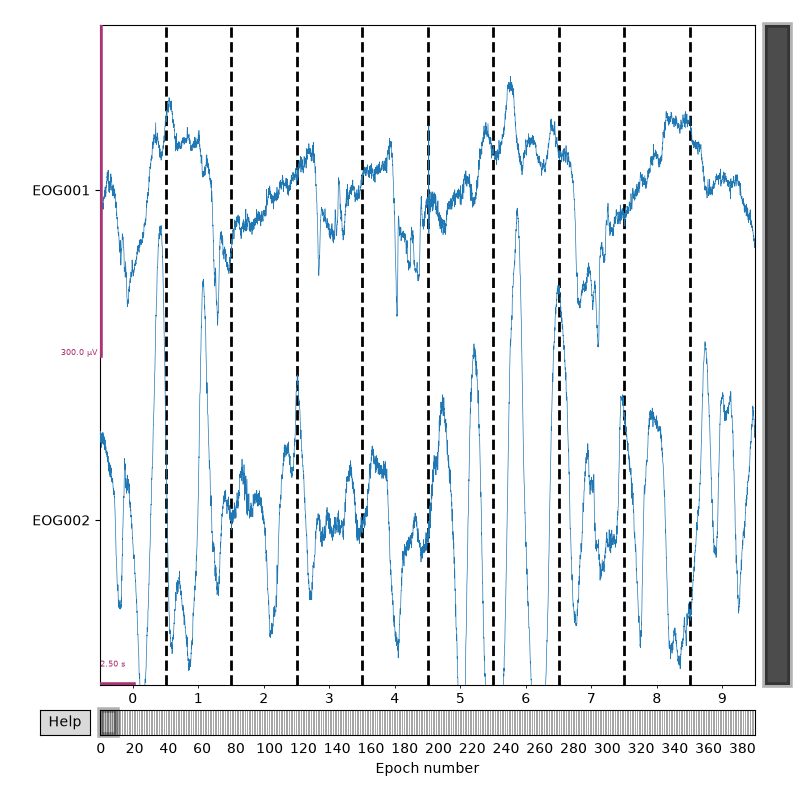

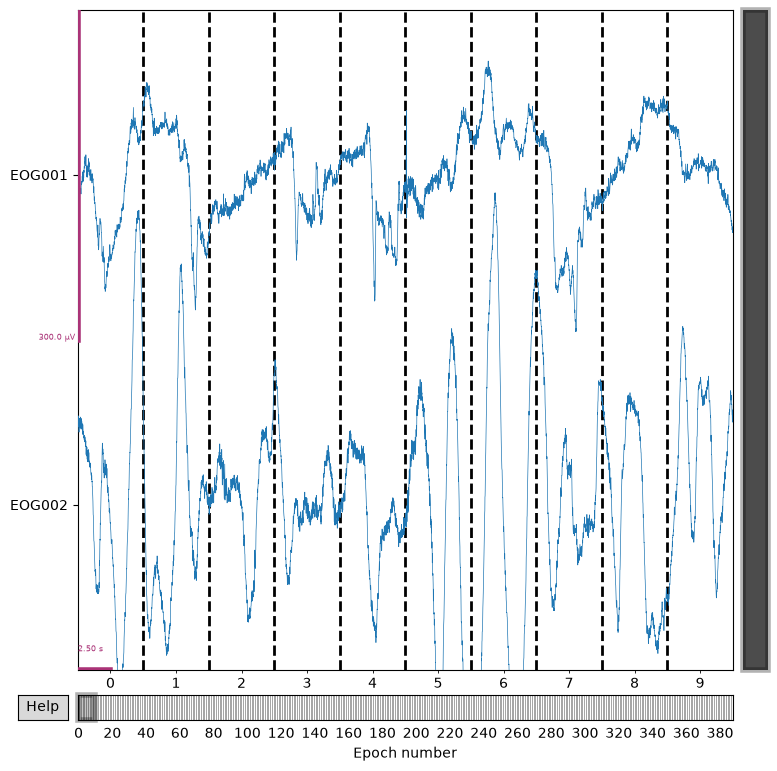

In [54]:
color_map = {"bodyscan": "tab:blue", "safeplace": "tab:green", "podcast": "tab:red"}
epoch_colors = [[color_map[s]] * len(epochs.ch_names) for s in md["stimulus"]]
epochs.plot(picks="eog", n_epochs=10, epoch_colors=epoch_colors)

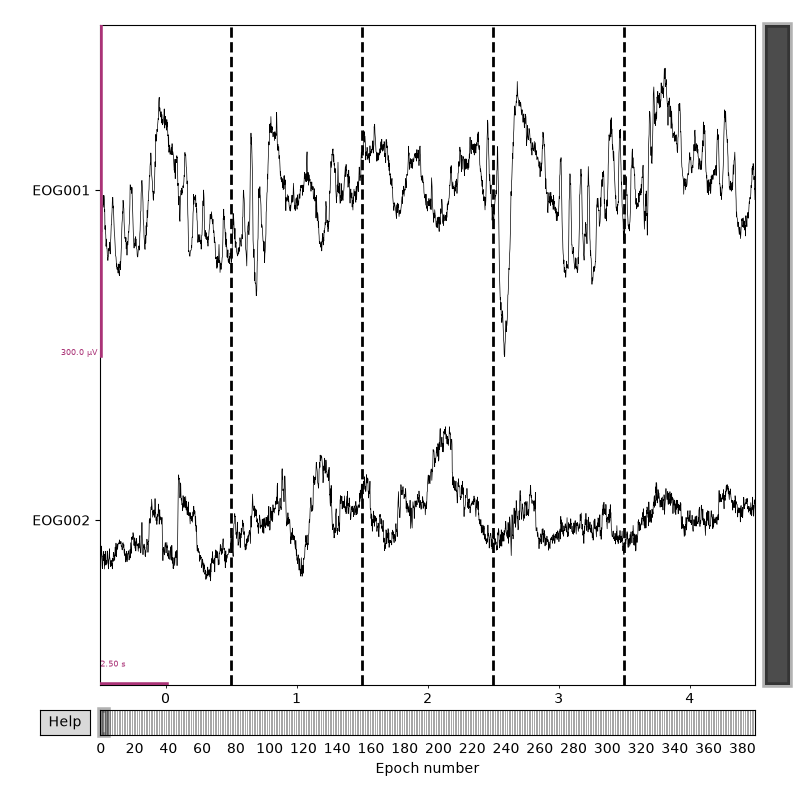

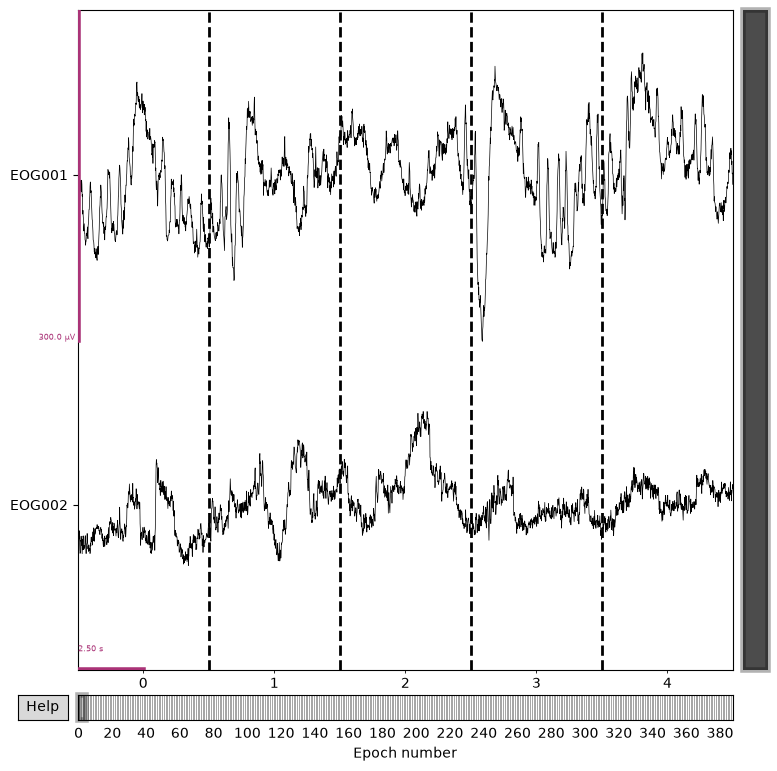

In [8]:
epochs.plot(picks="eog", n_epochs=5, n_channels=20)

In [19]:
print(epochs.metadata.columns)

Index(['label', 'segment_on_s', 'segment_off_s', 't_on', 't_off',
       'epoch_index_in_segment', 'stimulus', 'onset_code', 'end_code'],
      dtype='str')


In [24]:
md = epochs.metadata
print(md.head(10))
print(md["label"].value_counts())
print(md["stimulus"].value_counts())
print(md["onset_code"].value_counts())

       label  segment_on_s  segment_off_s   t_on  t_off  \
0  trial_000         30.48         754.58  30.48  35.48   
1  trial_000         30.48         754.58  35.48  40.48   
2  trial_000         30.48         754.58  40.48  45.48   
3  trial_000         30.48         754.58  45.48  50.48   
4  trial_000         30.48         754.58  50.48  55.48   
5  trial_000         30.48         754.58  55.48  60.48   
6  trial_000         30.48         754.58  60.48  65.48   
7  trial_000         30.48         754.58  65.48  70.48   
8  trial_000         30.48         754.58  70.48  75.48   
9  trial_000         30.48         754.58  75.48  80.48   

   epoch_index_in_segment  stimulus  onset_code  end_code  
0                       0  bodyscan          21        41  
1                       1  bodyscan          21        41  
2                       2  bodyscan          21        41  
3                       3  bodyscan          21        41  
4                       4  bodyscan          21   

In [9]:
md = epochs.metadata

bodyscan  = epochs[md["stimulus"] == "bodyscan"]
safeplace = epochs[md["stimulus"] == "safeplace"]
podcast   = epochs[md["stimulus"] == "podcast"]

print(md["stimulus"].value_counts())
print(md.groupby("stimulus")[["segment_on_s", "segment_off_s"]].first())

stimulus
bodyscan     144
safeplace    129
podcast      115
Name: count, dtype: int64
           segment_on_s  segment_off_s
stimulus                              
bodyscan          44.30         768.40
podcast         1768.04        2347.42
safeplace        948.30        1594.39


In [4]:
print(epochs.ch_names[-10:])
print(epochs.get_channel_types(unique=True))
print(epochs.copy().pick("eog").ch_names)

['STI009', 'STI010', 'STI011', 'STI012', 'STI013', 'STI014', 'STI015', 'STI016', 'STI101', 'envelope']
['eog', 'ecg', 'mag', 'grad', 'misc', 'stim']
['EOG001', 'EOG002']


In [ ]:
import numpy as np

md = epochs.metadata

def get_continuous(stim, picks):
    ep = epochs[md["stimulus"] == stim]
    data = ep.copy().pick(picks).get_data()      # (n_epochs, n_ch, 500)
    return np.concatenate(list(data), axis=-1)   # (n_ch, n_epochs*500)

eog = get_continuous("podcast", ["EOG001", "EOG002"])   # channel number, time points(2, 57500)
env = get_continuous("podcast", ["envelope"])           # (1, 57500)
print(eog.shape, env.shape)

(2, 57500) (1, 57500)


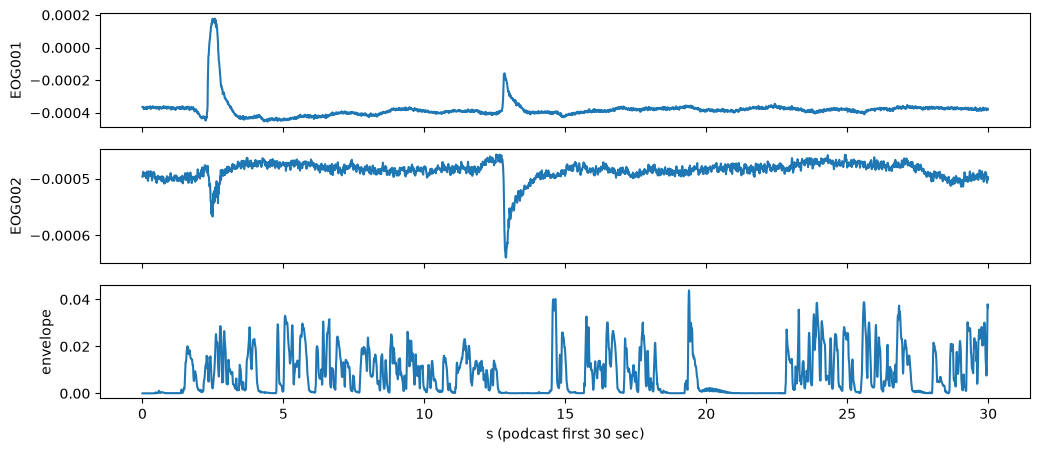

In [12]:
import matplotlib.pyplot as plt

t = np.arange(eog.shape[1]) / 100
fig, ax = plt.subplots(3, 1, figsize=(12, 5), sharex=True)
ax[0].plot(t[:3000], eog[0, :3000]); ax[0].set_ylabel("EOG001")
ax[1].plot(t[:3000], eog[1, :3000]); ax[1].set_ylabel("EOG002")
ax[2].plot(t[:3000], env[0, :3000]); ax[2].set_ylabel("envelope")
ax[2].set_xlabel("s (podcast first 30 sec)")
plt.show()

In [10]:
md = epochs.metadata.copy()
md["epoch_idx"] = range(len(md))   # 圖上的第幾個 epoch (從 0 開始)

print(md.groupby("stimulus")["epoch_idx"].agg(["min", "max", "count"]))

           min  max  count
stimulus                  
bodyscan     0  143    144
podcast    273  387    115
safeplace  144  272    129
